# Streamflow prediction for an Indian basin using NCEP FNL data (GDEX d083002)

This notebook trains an LSTM rainfall–runoff model (NeuralHydrology) for CAMELS-IND basin 3002. The same model is trained three times with different meteorological inputs, always with the same observed streamflow as the target:

| Setup | Meteorological inputs |
|---|---|
| A | FNL only (1° global analysis, grid cell nearest to the basin) |
| B | FNL + observed CAMELS-IND catchment rainfall |
| C | CAMELS-IND only (baseline) |

FNL does not contain precipitation (PRATE) before 12 June 2019. For the study period (2011–2018), precipitable water and soil moisture are therefore used as indirect rainfall information. Variables that are not available for the chosen dates are detected from the GDEX catalogue and skipped.

**Requirements**
1. A GDEX account and API token (https://gdex.ucar.edu, profile page).
2. The files `preprocessed/<BASIN_ID>.csv` and `attributes.csv`, created from CAMELS-IND with NeuralHydrology's `preprocess_camels_ind_dataset` function.
3. A GPU runtime is optional; training also runs on CPU.

Before the full download, every variable group is tested with a two-day request (Step 4). Downloaded data are cached in Google Drive, so an interrupted download can be resumed.

## Step 0: Configuration

In [ ]:
GDEX_TOKEN = "2bc775acb9432716506b8c233999"   # personal GDEX API token

BASIN_ID = "3002"

# Basin location (None = read from attributes.csv)
BASIN_LAT = None
BASIN_LON = None
BOX_DEG = 1.0            # half-width of the requested box around the basin (degrees)

# Study periods. FNL is available from 1999-07-30. DATA_START is one year before
# TRAIN_START to provide the 365-day input history (SEQ_LENGTH) for the first training day.
DATA_START  = "2011-01-01"
TRAIN_START = "2012-01-01"
TRAIN_END   = "2015-12-31"
VAL_START   = "2016-01-01"
VAL_END     = "2016-12-31"
TEST_START  = "2017-01-01"
TEST_END    = "2018-10-08"

EPOCHS = 50
SEQ_LENGTH = 365

USE_DRIVE_CACHE = True        # cache downloaded data in Google Drive
MAX_TOTAL_GB = 15             # download size limit (GB)
ALLOW_LARGE_DOWNLOAD = False  # allow downloads above the size limit
N_DOWNLOAD_WORKERS = 4

# Variable groups to exclude: "wind", "pwat", "soilw" ("tmp_rh" is always required)
SKIP_GROUPS = []

## Step 1: Install packages

In [ ]:
!pip install -q xarray netCDF4 requests
!pip install -q "git+https://github.com/neuralhydrology/neuralhydrology.git"

import neuralhydrology
from neuralhydrology.datasetzoo import camelsind  # check that the CAMELS-IND loader is available
print("NeuralHydrology ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 18.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 4.2 MB/s eta 0:00:00
NeuralHydrology ready


## Step 2: Helper functions
Functions for the GDEX API, reading the NetCDF files, daily aggregation and the NeuralHydrology set-up.

In [ ]:
# ---------------------------------------------------------------------------
# Helper functions
#   - GDEX API: submit subset requests, check their status, download, clean up
#   - reading NetCDF files and extracting the grid cell nearest to the basin
#   - aggregating 6-hourly FNL values to daily inputs
#   - writing NeuralHydrology datasets and configuration files
#
# Notes on the GDEX API (d083002):
#   - the submit endpoint needs a trailing slash; responses are under "data"
#   - one request can contain only one level type (e.g. HTGL:2 for 2 m)
#   - the dataset id "ds083.2" is tried first, "d083002" as fallback
#   - each request is delivered as one .tar bundle, downloaded once and unpacked
#   - files are deleted after the point value is extracted, and finished
#     requests are deleted on the server (limit on open requests)
# ---------------------------------------------------------------------------
import os, re, time, shutil, glob, tarfile, warnings
from datetime import datetime
from functools import reduce
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import requests
import xarray as xr

warnings.filterwarnings("ignore", category=FutureWarning)

API = "https://gdex.ucar.edu/api"
DATASET_ID_CANDIDATES = ["ds083.2", "d083002"]
FNL_FIRST_DATE = pd.Timestamp("1999-07-30")
_WORKING_DSID = None
OPEN_REQUESTS = set()
FAILED_RIDS = set()

# Variable groups (one level type per request). Groups that are not available for the
# study period, or that fail the test request in Step 4, are skipped; "core" is required.
CANDIDATE_GROUPS = [
    {"name": "tmp_rh", "params": ["TMP", "R H"],     "level": "HTGL:2",     "core": True},   # 2 m
    {"name": "wind",   "params": ["U GRD", "V GRD"], "level": "HTGL:10",    "core": False},  # 10 m
    {"name": "pwat",   "params": ["P WAT"],          "level": "EATM:0",     "core": False,   # whole column
     "alt_levels": ["EATM:0"]},
    {"name": "soilw",  "params": ["SOILW"],          "level": "DBLL:0.1,0", "core": False,   # 0-10 cm soil
     "alt_levels": ["DBLL:0.1,0", "DBLL:0,0.1", "DBLL:0.1"]},
    {"name": "prate",  "params": ["PRATE"],          "level": "SFC:0",      "core": False},  # only from 2019-06-12
]
GROUPS = list(CANDIDATE_GROUPS)

# (standard name, substrings of the upper-case variable name, exact short names)
VAR_PATTERNS = [
    ("prate", ["PRATE"],                   ["prate"]),
    ("ugrd",  ["UGRD", "U_GRD", "U GRD"],  ["u10", "u"]),
    ("vgrd",  ["VGRD", "V_GRD", "V GRD"],  ["v10", "v"]),
    ("tmp",   ["TMP"],                     ["t2m", "t"]),
    ("pwat",  ["PWAT", "P_WAT", "P WAT"],  ["pwat", "tcwv"]),
    ("soilw", ["SOILW"],                   ["soilw", "swvl1"]),
    ("rh",    ["RH", "R_H", "R H"],        ["r2", "r"]),
]


def standard_name(varname):
    up, low = str(varname).upper(), str(varname).lower()
    for std, subs, exact in VAR_PATTERNS:
        if low in exact or any(s in up for s in subs):
            return std
    return None


def expected_vars(group):
    return [standard_name(p) for p in group["params"]]


# ----------------------------- GDEX API ------------------------------------
def _req(method, url, retries=5, **kw):
    """HTTP request with retries for network errors and server (5xx) errors."""
    kw.setdefault("timeout", 120)
    last = None
    for i in range(retries):
        try:
            r = requests.request(method, url, **kw)
            if r.status_code >= 500:
                raise requests.HTTPError(f"server error {r.status_code}: {r.text[:200]}")
            return r
        except (requests.ConnectionError, requests.Timeout, requests.HTTPError) as e:
            last = e
            wait = min(60, 5 * 2 ** i)
            print(f"    GDEX problem ({str(e)[:120]}), retrying in {wait}s")
            time.sleep(wait)
    raise RuntimeError(f"GDEX unreachable after {retries} tries: {last}")


def _json(r):
    try:
        return r.json()
    except ValueError:
        return {"status": "error", "error_messages": [r.text[:500]], "data": {}}


def submit_request(params, level, date_start, date_end, box):
    """Submit a subset request (dates as YYYYMMDDHHMM) and return the request id."""
    global _WORKING_DSID
    nlat, slat, wlon, elon = box
    base = {"date": f"{date_start}/to/{date_end}", "param": "/".join(params),
            "level": level, "oformat": "netCDF",
            "nlat": nlat, "slat": slat, "wlon": wlon, "elon": elon}
    candidates = [_WORKING_DSID] if _WORKING_DSID else DATASET_ID_CANDIDATES
    errors = []
    for dsid in candidates:
        body = _json(_req("POST", f"{API}/submit/?token={GDEX_TOKEN}",
                          json=dict(base, dataset=dsid)))
        data = body.get("data") or {}
        rid = data.get("request_id") if isinstance(data, dict) else None
        if body.get("status") == "ok" and rid:
            if rid in FAILED_RIDS:
                raise RuntimeError(f"GDEX handed back request {rid}, which already failed "
                                   "(identical request); trying smaller pieces instead")
            _WORKING_DSID = dsid
            OPEN_REQUESTS.add(rid)
            return rid
        errors.append(f"dataset={dsid}: {body.get('error_messages')}")
    msg = "; ".join(errors)
    if "token" in msg.lower() or "auth" in msg.lower():
        msg += "\n-> Check GDEX_TOKEN in the configuration cell."
    if "open request" in msg.lower() or "limit" in msg.lower():
        msg += "\n-> Too many open requests. Run the cleanup cell at the bottom, then retry."
    raise RuntimeError("GDEX rejected the request: " + msg)


def wait_for_request(rid, poll=20, timeout_min=60):
    t0, last = time.time(), None
    while True:
        body = _json(_req("GET", f"{API}/status/{rid}?token={GDEX_TOKEN}"))
        data = body.get("data") or {}
        status = data.get("status") if isinstance(data, dict) else None
        status = status or f"unknown ({body.get('error_messages')})"
        if status != last:
            print(f"    request {rid}: {status}")
            last = status
        if status == "Completed":
            return
        if any(w in status.lower() for w in ("error", "deleted", "purge", "fail", "not found")):
            FAILED_RIDS.add(rid)
            if isinstance(data, dict):
                note = (data.get("subset_info") or {}).get("note") or data.get("rinfo")
                if note:
                    print("    GDEX details:", " ".join(str(note).split())[:300])
            raise RuntimeError(f"request {rid} ended with status: {status}")
        if time.time() - t0 > timeout_min * 60:
            raise TimeoutError(f"request {rid} still '{status}' after {timeout_min} min")
        time.sleep(poll)


def list_request_files(rid):
    body = _json(_req("GET", f"{API}/get_req_files/{rid}?token={GDEX_TOKEN}"))
    data = body.get("data") or {}
    files = (data.get("web_files") if isinstance(data, dict) else None) or []
    data_files = [f for f in files
                  if str(f.get("wfile", "")).endswith((".nc", ".nc4", ".grib2", ".grb2"))]
    return sorted(data_files or files, key=lambda f: str(f.get("wfile", "")))


def purge_request(rid):
    try:
        r = requests.delete(f"{API}/purge/{rid}?token={GDEX_TOKEN}", timeout=60)
        print(f"    cleaned up request {rid} (HTTP {r.status_code})")
    except Exception as e:
        print(f"    could not clean up {rid} ({e}); it will expire on its own")
    OPEN_REQUESTS.discard(rid)


def download_file(url, path, retries=4):
    for i in range(retries):
        try:
            with requests.get(url, stream=True, timeout=300) as r:
                r.raise_for_status()
                tmp = path + ".part"
                with open(tmp, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        if chunk:
                            f.write(chunk)
            os.replace(tmp, path)
            return path
        except Exception:
            if i == retries - 1:
                raise
            time.sleep(5 * 2 ** i)


def load_metadata():
    body = _json(_req("GET", f"{API}/metadata/d083002"))
    data = body.get("data") or {}
    return (data.get("data") if isinstance(data, dict) else None) or []


def check_group_coverage(group, meta, start, end):
    """Check in the GDEX catalogue whether a group covers the study period.
    Returns (ok, level_string, message)."""
    s_num = int(pd.Timestamp(start).strftime("%Y%m%d%H%M"))
    e_num = int(pd.Timestamp(end).strftime("%Y%m%d0000"))
    want_type, want_val = group["level"].split(":", 1)
    for p in group["params"]:
        entries = [m for m in meta if m.get("param") == p]
        if not entries:
            return False, None, f"{p} is not in the d083002 catalogue"
        covering = [m for m in entries
                    if int(m.get("start_date") or 0) <= s_num and int(m.get("end_date") or 0) >= e_num]
        if not covering:
            first = min(int(m.get("start_date") or 0) for m in entries)
            last = max(int(m.get("end_date") or 0) for m in entries)
            return False, None, (f"{p} exists only {str(first)[:8]}..{str(last)[:8]}, "
                                 f"not for your whole period")
        levels = [lv for m in covering for lv in (m.get("levels") or [])]
        if levels and not any(lv.get("level") == want_type and str(lv.get("level_value")) == want_val
                              for lv in levels):
            print(f"    note: {p} catalogue doesn't list level {group['level']}; "
                  "the 2-day test in Step 4 will decide")
    return True, group["level"], "ok"


# ------------------------- reading the files -------------------------------
_TS = re.compile(r"(\d{8})_(\d{2})")


def timestamp_from_name(name):
    m = _TS.search(os.path.basename(str(name)))
    if not m:
        return None
    return pd.Timestamp(datetime.strptime(m.group(1) + m.group(2), "%Y%m%d%H"))


def _open(path):
    try:
        return xr.open_dataset(path, decode_timedelta=False)
    except Exception as e1:
        try:
            return xr.open_dataset(path, engine="cfgrib", decode_timedelta=False)
        except Exception as e2:
            raise RuntimeError(f"cannot open {os.path.basename(path)}: {e1} | {e2}")


def _find_dim(obj, prefix):
    for name in list(obj.dims) + list(obj.coords):
        if str(name).lower().startswith(prefix):
            return name
    return None


def _time_from_ds(ds):
    for c in ds.coords:
        if "time" in str(c).lower():
            try:
                return pd.Timestamp(pd.to_datetime(np.asarray(ds[c].values).ravel()[0]))
            except Exception:
                pass
    return None


def extract_point(path, lat, lon):
    """Return {variable: value} for the grid cell nearest to (lat, lon)."""
    out = {}
    with _open(path) as ds:
        for v in ds.data_vars:
            std = standard_name(v)
            da = ds[v]
            latd, lond = _find_dim(da, "lat"), _find_dim(da, "lon")
            if std is None or latd is None or lond is None:
                continue
            lons = np.asarray(ds[lond].values, dtype=float)
            target_lon = lon % 360 if np.nanmax(lons) > 180 else lon
            try:
                pt = da.sel({latd: lat, lond: target_lon}, method="nearest")
            except Exception:
                lats = np.asarray(ds[latd].values, dtype=float)
                pt = da.isel({latd: int(np.nanargmin(np.abs(lats - lat))),
                              lond: int(np.nanargmin(np.abs(lons - target_lon)))})
            vals = np.asarray(pt.values, dtype=float).ravel()
            vals = vals[np.isfinite(vals)]
            out[std] = float(vals[0]) if vals.size else np.nan
        out["_time"] = _time_from_ds(ds)
    return out


def inspect_file(path, lat, lon):
    size_mb = os.path.getsize(path) / 1e6
    with _open(path) as ds:
        latd, lond = _find_dim(ds, "lat"), _find_dim(ds, "lon")
        n_lat = int(ds.sizes.get(latd, 0)) if latd else 0
        n_lon = int(ds.sizes.get(lond, 0)) if lond else 0
        var_names = list(ds.data_vars)
    vals = extract_point(path, lat, lon)
    vals.pop("_time", None)
    return size_mb, n_lat, n_lon, var_names, vals


DATA_EXT = (".nc", ".nc4", ".grib2", ".grb2")


def fetch_files(wfs, dest_dir, workers=4):
    """Download the files of a request and return the paths of the data files.
    The listed files usually share one .tar bundle, so each unique link is
    downloaded once and unpacked."""
    os.makedirs(dest_dir, exist_ok=True)
    urls = list(dict.fromkeys(wf["web_path"] for wf in wfs))      # unique links, original order
    targets = [os.path.join(dest_dir, f"part{i}_" + (os.path.basename(u.split("?")[0]) or "file"))
               for i, u in enumerate(urls)]
    if len(urls) > 1:
        with ThreadPoolExecutor(max_workers=workers) as ex:
            list(ex.map(download_file, urls, targets))
    else:
        download_file(urls[0], targets[0])
    out = []
    for path in targets:
        if tarfile.is_tarfile(path):
            with tarfile.open(path) as tf:
                for m in tf.getmembers():
                    base = os.path.basename(m.name)
                    if not m.isfile() or "PaxHeaders" in m.name or base.startswith("._"):
                        continue
                    target = os.path.join(dest_dir, base)          # file name only, no paths from the archive
                    with tf.extractfile(m) as src, open(target, "wb") as dst:
                        shutil.copyfileobj(src, dst)
                    out.append(target)
            os.remove(path)
        else:
            out.append(path)
    data = [p for p in out if p.endswith(DATA_EXT)]
    return sorted(data or out)


def fetch_group_period(group, start, end, box, lat, lon, cache_path, workers=4):
    """Download one variable group for one period as a point time series (cached)."""
    if cache_path and os.path.exists(cache_path):
        df = pd.read_csv(cache_path, parse_dates=["time"])
        print(f"  [{group['name']} {start[:8]}-{end[:8]}] loaded from cache ({len(df)} steps)")
        return df
    print(f"  [{group['name']} {start[:8]}-{end[:8]}] submitting request ...")
    rid = submit_request(group["params"], group["level"], start, end, box)
    tmpdir = os.path.join(WORK, f"tmp_{group['name']}_{rid}")
    try:
        wait_for_request(rid)
        wfs = list_request_files(rid)
        if not wfs:
            raise RuntimeError(f"request {rid} completed but returned no files")
        paths = fetch_files(wfs, tmpdir, workers)
        print(f"    {len(paths)} data files received")
        rows, failed = [], []
        for i, pth in enumerate(paths, 1):
            try:
                vals = extract_point(pth, lat, lon)
                file_time = vals.pop("_time", None)
                vals["time"] = timestamp_from_name(pth) or file_time
                rows.append(vals)
            except Exception as e:
                failed.append((os.path.basename(pth), str(e)[:150]))
            if i % 500 == 0 or i == len(paths):
                print(f"      {i}/{len(paths)} files read")
        if failed:
            print(f"    WARNING: {len(failed)} files could not be read, e.g. {failed[:2]}")
        if not rows:
            raise RuntimeError("none of the files could be read")
        df = pd.DataFrame(rows).dropna(subset=["time"])
        df = df.sort_values("time").drop_duplicates("time")
        missing = [v for v in expected_vars(group) if v not in df.columns]
        if missing:
            raise RuntimeError(f"variables {missing} not found; columns seen: {list(df.columns)}")
        if cache_path:
            df.to_csv(cache_path, index=False)
        return df
    finally:
        purge_request(rid)
        shutil.rmtree(tmpdir, ignore_errors=True)


FAILED_CHUNKS = []


def split_period(start, end):
    """Split a period: year -> quarters, quarter -> months, month -> no further split."""
    s, e = pd.Timestamp(start[:8]), pd.Timestamp(end[:8])
    days = (e - s).days + 1
    if days > 100:
        freq = "QS"
    elif days > 35:
        freq = "MS"
    else:
        return []
    starts = sorted(set([s] + list(pd.date_range(s, e, freq=freq))))
    parts = []
    for i, st in enumerate(starts):
        en = starts[i + 1] - pd.Timedelta(days=1) if i + 1 < len(starts) else e
        parts.append((f"{st:%Y%m%d}0000", f"{en:%Y%m%d}1800"))
    return parts


def _empty_group_frame(group):
    cols = {"time": pd.Series(dtype="datetime64[ns]")}
    cols.update({v: pd.Series(dtype=float) for v in expected_vars(group)})
    return pd.DataFrame(cols)


def fetch_with_fallback(group, start, end, box, lat, lon, cache_prefix, workers=4):
    """fetch_group_period with a fallback: if a request fails, the period is split
    into quarters and then months; a month that still fails is left as a gap."""
    cache = f"{cache_prefix}_{group['name']}_{start[:8]}_{end[:8]}.csv"
    # An identical resubmission returns the same failed request, so the period is split instead.
    try:
        return fetch_group_period(group, start, end, box, lat, lon, cache, workers)
    except (RuntimeError, TimeoutError) as e:
        if "unreachable" in str(e).lower():
            raise RuntimeError(str(e) + "\n-> GDEX is down right now. Wait a while and run "
                               "this cell again; finished chunks are cached.")
        print(f"    failed: {str(e)[:200]}")
    parts = split_period(start, end)
    if not parts:
        print(f"    skipping {group['name']} {start[:8]}-{end[:8]}; it will be a gap in the data")
        FAILED_CHUNKS.append((group["name"], start[:8], end[:8]))
        return _empty_group_frame(group)
    print(f"    splitting {group['name']} {start[:8]}-{end[:8]} into {len(parts)} smaller requests")
    n_before = len(FAILED_CHUNKS)
    dfs = [fetch_with_fallback(group, s_, e_, box, lat, lon, cache_prefix, workers) for s_, e_ in parts]
    dfs = [d for d in dfs if len(d)]
    df = pd.concat(dfs, ignore_index=True) if dfs else _empty_group_frame(group)
    if len(FAILED_CHUNKS) == n_before and len(df):
        df.to_csv(cache, index=False)
    return df


def year_chunks(start, end):
    """Split [start, end] into yearly date ranges for GDEX requests."""
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    chunks = []
    for year in range(start.year, end.year + 1):
        s = max(start, pd.Timestamp(f"{year}-01-01"))
        e = min(end, pd.Timestamp(f"{year}-12-31"))
        chunks.append((year, f"{s:%Y%m%d}0000", f"{e:%Y%m%d}1800"))
    return chunks


# --------------------------- daily inputs ----------------------------------
def build_daily(raw, start, end):
    """Aggregate 6-hourly point values to daily inputs (CAMELS-IND names and units).
    Gaps of up to 3 days are filled by linear interpolation."""
    df = raw.set_index("time").sort_index()
    cols = {}
    if "tmp" in df:
        t = df["tmp"].astype(float)
        if t.median() > 150:                      # Kelvin -> Celsius
            t = t - 273.15
        cols.update(tmax=t.resample("1D").max(), tmin=t.resample("1D").min(),
                    tavg=t.resample("1D").mean())
    if "rh" in df:
        cols["rel_hum"] = df["rh"].astype(float).resample("1D").mean()
    if "ugrd" in df and "vgrd" in df:
        wind = np.sqrt(df["ugrd"].astype(float) ** 2 + df["vgrd"].astype(float) ** 2)
        cols["wind"] = wind.resample("1D").mean()
    if "pwat" in df:                              # kg m-2 = mm of water in the air column
        cols["pwat"] = df["pwat"].astype(float).resample("1D").mean()
    if "soilw" in df:                             # volumetric fraction (m3/m3)
        cols["soilw"] = df["soilw"].astype(float).resample("1D").mean()
    if "prate" in df:                             # kg m-2 s-1 -> mm/day
        cols["prcp"] = (df["prate"].astype(float).clip(lower=0) * 86400).resample("1D").mean()
    daily = pd.DataFrame(cols)
    full = pd.date_range(pd.Timestamp(start), pd.Timestamp(end), freq="D")
    daily = daily.reindex(full)
    gaps_before = int(daily.isna().any(axis=1).sum())
    daily = daily.interpolate(limit=3, limit_area="inside")
    gaps_after = int(daily.isna().any(axis=1).sum())
    daily.index.name = "date"
    return daily, gaps_before, gaps_after


# ---------------------- NeuralHydrology set-up -----------------------------
def write_nh_dataset(root, forcing, target, attributes_path, basin_id):
    os.makedirs(os.path.join(root, "preprocessed"), exist_ok=True)
    df = forcing.join(target.reindex(forcing.index), how="left")
    df.index.name = "date"
    df.to_csv(os.path.join(root, "preprocessed", f"{basin_id}.csv"), index_label="date")
    shutil.copy(attributes_path, os.path.join(root, "attributes.csv"))
    return df


def write_config(name, data_dir, inputs, basin_file, periods, epochs, seq_length,
                 device, run_root):
    d = lambda s: pd.Timestamp(s).strftime("%d/%m/%Y")
    lr = {0: 0.01, max(1, int(epochs * 0.6)): 0.005, max(2, int(epochs * 0.8)): 0.001}
    lr_lines = "\n".join(f"  {k}: {v}" for k, v in sorted(lr.items()))
    input_lines = "\n".join(f"  - {c}" for c in inputs)
    text = f"""experiment_name: {name}
run_dir: {run_root}
train_basin_file: {basin_file}
validation_basin_file: {basin_file}
test_basin_file: {basin_file}
train_start_date: "{d(periods['train'][0])}"
train_end_date: "{d(periods['train'][1])}"
validation_start_date: "{d(periods['val'][0])}"
validation_end_date: "{d(periods['val'][1])}"
test_start_date: "{d(periods['test'][0])}"
test_end_date: "{d(periods['test'][1])}"
device: {device}
validate_every: 5
validate_n_random_basins: 1
metrics:
  - NSE
  - KGE
model: cudalstm
head: regression
output_activation: linear
hidden_size: 20
initial_forget_bias: 3
output_dropout: 0.4
optimizer: Adam
loss: MSE
learning_rate:
{lr_lines}
batch_size: 256
epochs: {epochs}
clip_gradient_norm: 1
predict_last_n: 1
seq_length: {seq_length}
num_workers: 2
log_interval: 5
log_tensorboard: False
log_n_figures: 0
save_weights_every: 1
dataset: camels_ind
data_dir: {data_dir}
dynamic_inputs:
{input_lines}
target_variables:
  - streamflow_mm_day
clip_targets_to_zero:
  - streamflow_mm_day
"""
    path = os.path.join(os.path.dirname(basin_file), f"{name}.yml")
    with open(path, "w") as f:
        f.write(text)
    return path


def latest_run_dir(run_root, name):
    runs = sorted(glob.glob(os.path.join(run_root, f"{name}_*")), key=os.path.getmtime)
    if not runs:
        raise RuntimeError(f"no run folder found for {name} in {run_root}")
    return runs[-1]


def load_test_results(run_dir, basin_id):
    import pickle
    paths = sorted(glob.glob(os.path.join(run_dir, "test", "model_epoch*", "test_results.p")))
    if not paths:
        raise RuntimeError(f"no test_results.p in {run_dir}; did evaluation run?")
    with open(paths[-1], "rb") as f:
        results = pickle.load(f)
    xr_res = results[basin_id]["1D"]["xr"]
    obs = xr_res["streamflow_mm_day_obs"].isel(time_step=-1)
    sim = xr_res["streamflow_mm_day_sim"].isel(time_step=-1)
    return obs, sim


def usable_inputs(df, inputs, period, label):
    """Remove inputs that are empty or constant in the training period
    (NeuralHydrology scales each input by its standard deviation)."""
    part = df.loc[period[0]:period[1]]
    keep = []
    for c in inputs:
        s = part[c]
        if s.notna().sum() == 0:
            print(f"  [{label}] dropping '{c}': no data in the training period")
        elif not (s.std(skipna=True) > 0):
            print(f"  [{label}] dropping '{c}': constant in the training period")
        else:
            keep.append(c)
    if not keep:
        raise RuntimeError(f"[{label}] no usable input variables left.")
    return keep


def count_valid_samples(df, inputs, period, seq_length):
    """Number of days in `period` with observed flow and complete inputs for the
    preceding seq_length days."""
    x_ok = df[inputs].notna().all(axis=1).astype(int)
    window_ok = x_ok.rolling(seq_length).sum() == seq_length
    y_ok = df["streamflow_mm_day"].notna()
    return int((window_ok & y_ok).loc[period[0]:period[1]].sum())

## Step 3: Basin files, basin location and study periods

In [ ]:
import os, re
import pandas as pd

WORK = "/content/nh_fnl"
os.makedirs(WORK, exist_ok=True)

CACHE_DIR = os.path.join(WORK, "fnl_cache")
if USE_DRIVE_CACHE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CACHE_DIR = "/content/drive/MyDrive/fnl_cache"
    except Exception as e:
        print("Google Drive not mounted, caching inside this session only:", e)
os.makedirs(CACHE_DIR, exist_ok=True)

# ---- upload ----
BASIN_CSV = os.path.join(WORK, f"{BASIN_ID}.csv")
ATTR_CSV = os.path.join(WORK, "attributes.csv")
if not (os.path.exists(BASIN_CSV) and os.path.exists(ATTR_CSV)):
    from google.colab import files
    print(f"Select BOTH files: preprocessed/{BASIN_ID}.csv and attributes.csv")
    for name, content in files.upload().items():
        header = content[:4000].decode("utf-8", errors="ignore").splitlines()[0].lower()
        if "gauge_id" in header:
            dest = ATTR_CSV
        elif "streamflow_mm_day" in header:
            dest = BASIN_CSV
        else:
            print(f"  ignoring {name} (not a basin file or attributes file)")
            continue
        with open(dest, "wb") as f:
            f.write(content)
        print(f"  {name} -> {dest}")
missing = [p for p in (BASIN_CSV, ATTR_CSV) if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"Still missing {missing}. Re-run this cell and select both files.")

# ---- basin location ----
attrs = pd.read_csv(ATTR_CSV)
attrs["gauge_id"] = attrs["gauge_id"].astype(str).str.replace(r"\.0$", "", regex=True)
row = attrs[attrs["gauge_id"] == str(BASIN_ID)]
if row.empty:
    raise ValueError(f"Basin {BASIN_ID} is not in attributes.csv")

def _pick(cols):
    for key in ("cent", "cwc", "gauge"):
        for c in cols:
            if key in c.lower():
                return c
    return cols[0] if cols else None

lat_cols = [c for c in attrs.columns if re.search(r"(^|_)lat(itude)?(_|$)", c.lower())]
lon_cols = [c for c in attrs.columns if re.search(r"(^|_)(lon|long|longitude)(_|$)", c.lower())]
if BASIN_LAT is None or BASIN_LON is None:
    lat_c, lon_c = _pick(lat_cols), _pick(lon_cols)
    if lat_c is None or lon_c is None:
        raise ValueError(f"No lat/lon columns found (saw {list(attrs.columns)[:20]}...). "
                         "Set BASIN_LAT / BASIN_LON in Step 0.")
    BASIN_LAT, BASIN_LON = float(row[lat_c].iloc[0]), float(row[lon_c].iloc[0])
    print(f"Location from attributes.csv columns '{lat_c}'/'{lon_c}' (candidates: {lat_cols} / {lon_cols})")
print(f"Basin {BASIN_ID}: lat {BASIN_LAT:.3f}, lon {BASIN_LON:.3f}")
if not (5 <= BASIN_LAT <= 38 and 65 <= BASIN_LON <= 100):
    print("WARNING: that location is outside India. Check BASIN_LAT / BASIN_LON.")
BOX = (round(BASIN_LAT + BOX_DEG, 2), round(BASIN_LAT - BOX_DEG, 2),
       round(BASIN_LON - BOX_DEG, 2), round(BASIN_LON + BOX_DEG, 2))   # (nlat, slat, wlon, elon)

# ---- basin record and periods ----
basin_df = pd.read_csv(BASIN_CSV, index_col="date", parse_dates=True)
q = basin_df["streamflow_mm_day"]
print(f"Observed streamflow available {q.first_valid_index():%Y-%m-%d} to {q.last_valid_index():%Y-%m-%d} "
      f"({int(q.notna().sum())} valid days)")

dates = [pd.Timestamp(x) for x in (DATA_START, TRAIN_START, TRAIN_END, VAL_START, VAL_END, TEST_START, TEST_END)]
if dates[0] < FNL_FIRST_DATE:
    raise ValueError(f"FNL starts {FNL_FIRST_DATE:%Y-%m-%d}; move DATA_START later.")
if not (dates[0] <= dates[1] < dates[2] < dates[3] <= dates[4] < dates[5] <= dates[6]):
    raise ValueError("Periods must be in order: DATA_START <= TRAIN < VAL < TEST.")
PERIODS = {"train": (TRAIN_START, TRAIN_END), "val": (VAL_START, VAL_END), "test": (TEST_START, TEST_END)}
for k, (s, e) in PERIODS.items():
    part = q.loc[s:e]
    zero_share = float((part == 0).mean()) if part.notna().any() else float("nan")
    print(f"  {k:5s} {s} to {e}: {int(part.notna().sum())} days with observed flow, "
          f"{zero_share:.0%} of them zero-flow")
    if part.notna().sum() < 90:
        print(f"  WARNING: very little observed flow in the {k} period; pick other dates.")

Google Drive not mounted, caching inside this session only: Error: credential propagation was unsuccessful
Select BOTH files: preprocessed/3002.csv and attributes.csv


Saving 3002.csv to 3002.csv
Saving attributes.csv to attributes.csv
  3002.csv -> /content/nh_fnl/3002.csv
  attributes.csv -> /content/nh_fnl/attributes.csv
Location from attributes.csv columns 'cwc_lat'/'cwc_lon' (candidates: ['cwc_lat', 'ghi_lat'] / ['cwc_lon', 'ghi_lon'])
Basin 3002: lat 19.297, lon 81.789
Observed streamflow available 1993-06-01 to 2018-10-08 (8226 valid days)
  train 2012-01-01 to 2015-12-31: 889 days with observed flow, 44% of them zero-flow
  val   2016-01-01 to 2016-12-31: 142 days with observed flow, 8% of them zero-flow
  test  2017-01-01 to 2018-10-08: 407 days with observed flow, 30% of them zero-flow


## Step 4: Variable availability and test requests
The GDEX catalogue is checked first: variables that do not cover the whole study period are skipped (for example PRATE, which starts in June 2019). Each remaining variable group is then tested with a two-day request, trying alternative level names if needed. Only groups that pass are downloaded in Step 5.

In [ ]:
meta = load_metadata()
print(f"GDEX catalogue loaded ({len(meta)} entries)\n")
GROUPS = []
for g0 in CANDIDATE_GROUPS:
    g = dict(g0)
    if g["name"] in SKIP_GROUPS and not g["core"]:
        print(f"  {g['name']:7s} SKIPPED: listed in SKIP_GROUPS")
        continue
    ok, level, msg = check_group_coverage(g, meta, DATA_START, TEST_END)
    if ok:
        GROUPS.append(g)
        print(f"  {g['name']:7s} covers your dates")
    else:
        print(f"  {g['name']:7s} SKIPPED: {msg}")
        if g["core"]:
            raise RuntimeError(f"Core variables ({g['params']}) unavailable for these dates; change the periods.")

t0 = pd.Timestamp(DATA_START)
d0, d1 = f"{t0:%Y%m%d}0000", f"{t0 + pd.Timedelta(days=1):%Y%m%d}1800"
passed, sizes, grids = [], [], []
for g in GROUPS:
    levels_to_try = list(dict.fromkeys([g["level"]] + g.get("alt_levels", [])))
    ok = False
    for level in levels_to_try:
        print(f"\n  testing {g['name']} at level {level} ...")
        sample_dir = os.path.join(WORK, f"sample_{g['name']}")
        shutil.rmtree(sample_dir, ignore_errors=True)
        rid = None
        try:
            rid = submit_request(g["params"], level, d0, d1, BOX)
            wait_for_request(rid, poll=10)
            wfs = list_request_files(rid)
            got = fetch_files(wfs, sample_dir) if wfs else []
            if not got:
                raise RuntimeError("no files returned")
            size_mb, n_lat, n_lon, var_names, vals = inspect_file(got[0], BASIN_LAT, BASIN_LON)
            missing_v = [v for v in expected_vars(g) if v not in vals]
            if missing_v:
                raise RuntimeError(f"could not recognise {missing_v} among {var_names}")
            print(f"    OK: {len(got)} files, {size_mb * 1000:.1f} KB each, grid {n_lat} x {n_lon}, values {vals}")
            g["level"] = level
            sizes.append(size_mb); grids.append(n_lat * n_lon); passed.append(g)
            ok = True
            break
        except Exception as e:
            print(f"    failed: {str(e)[:250]}")
        finally:
            if rid is not None:
                purge_request(rid)
    if not ok:
        if g["core"]:
            raise RuntimeError(f"Core group {g['name']} failed its test; see messages above.")
        print(f"  -> {g['name']} dropped")
GROUPS = passed
print(f"\nDataset id accepted by GDEX: '{_WORKING_DSID}'")
print("Will download:", [(g["name"], g["level"]) for g in GROUPS])

SUBSET_OK = max(grids) <= 400
n_days = (pd.Timestamp(TEST_END) - pd.Timestamp(DATA_START)).days + 1
total_files = n_days * 4 * len(GROUPS)
est_gb = (sum(sizes) / len(sizes)) * total_files / 1000
print(f"Full run: about {total_files} files, about {est_gb:.2f} GB in total.")
if SUBSET_OK:
    print("Bounding box is applied. Safe to continue with Step 5.")
else:
    print("GDEX did NOT apply the bounding box (it sent the full grid).")
    if est_gb > MAX_TOTAL_GB and not ALLOW_LARGE_DOWNLOAD:
        raise RuntimeError(
            f"That would mean downloading about {est_gb:.0f} GB. Options: (1) shorten "
            "DATA_START..TEST_END in Step 0, or (2) set ALLOW_LARGE_DOWNLOAD = True "
            "(files are reduced to one point and deleted as they arrive, but expect hours).")

GDEX catalogue loaded (192 entries)

  tmp_rh  covers your dates
  wind    covers your dates
  pwat    covers your dates
  soilw   covers your dates
  prate   SKIPPED: PRATE exists only 20190612..20261008, not for your whole period

  testing tmp_rh at level HTGL:2 ...
    request 933015: Queued for Processing
    request 933015: Completed
    OK: 8 files, 1.7 KB each, grid 2 x 2, values {'tmp': 286.5299987792969, 'rh': 84.5}
    cleaned up request 933015 (HTTP 200)

  testing wind at level HTGL:10 ...
    request 933016: Queued for Processing
    request 933016: Completed
    OK: 8 files, 1.7 KB each, grid 2 x 2, values {'ugrd': 0.8899999856948853, 'vgrd': -0.3499999940395355}
    cleaned up request 933016 (HTTP 200)

  testing pwat at level EATM:0 ...
    request 933017: Queued for Processing
    request 933017: Completed
    OK: 8 files, 1.4 KB each, grid 2 x 2, values {'pwat': 22.299999237060547}
    cleaned up request 933017 (HTTP 200)

  testing soilw at level DBLL:0.1,0 ...
    

## Step 5: Download FNL data for the full period
One request per variable group per year. Each completed chunk is cached, so the cell can be re-run after an interruption and continues where it stopped.

In [ ]:
import time
from functools import reduce

cache_prefix = os.path.join(CACHE_DIR, f"{BASIN_ID}_{BASIN_LAT:.2f}_{BASIN_LON:.2f}")
frames = {g["name"]: [] for g in GROUPS}
FAILED_CHUNKS.clear()
t_start = time.time()
for year, s, e in year_chunks(DATA_START, TEST_END):
    for g in GROUPS:
        frames[g["name"]].append(
            fetch_with_fallback(g, s, e, BOX, BASIN_LAT, BASIN_LON, cache_prefix, workers=N_DOWNLOAD_WORKERS))
print(f"Done in {(time.time() - t_start) / 60:.1f} min")
if FAILED_CHUNKS:
    print("Periods GDEX could not deliver (left as gaps):", FAILED_CHUNKS)
    print("Re-running this cell later will try just those periods again.")

group_dfs = []
for name, v in frames.items():
    v = [d for d in v if len(d)]
    if v:
        group_dfs.append(pd.concat(v, ignore_index=True).drop_duplicates("time"))
    else:
        print(f"WARNING: no data at all for {name}; it will be left out.")
raw = reduce(lambda a, b: pd.merge(a, b, on="time", how="outer"), group_dfs).sort_values("time")
raw.to_csv(os.path.join(WORK, f"fnl_6hourly_{BASIN_ID}.csv"), index=False)
print(f"{len(raw)} six-hourly time steps, columns: {list(raw.columns)}")

  [tmp_rh 20110101-20111231] submitting request ...
    request 933022: Queued for Processing
    request 933022: Completed
    1460 data files received
      500/1460 files read
      1000/1460 files read
      1460/1460 files read
    cleaned up request 933022 (HTTP 200)
  [wind 20110101-20111231] submitting request ...
    request 933023: Queued for Processing
    request 933023: Completed
    1460 data files received
      500/1460 files read
      1000/1460 files read
      1460/1460 files read
    cleaned up request 933023 (HTTP 200)
  [pwat 20110101-20111231] submitting request ...
    request 933024: Queued for Processing
    request 933024: Completed
    1460 data files received
      500/1460 files read
      1000/1460 files read
      1460/1460 files read
    cleaned up request 933024 (HTTP 200)
  [soilw 20110101-20111231] submitting request ...
    request 933025: Queued for Processing
    request 933025: Completed
    1460 data files received
      500/1460 files read
    

## Step 6: Daily aggregation and comparison with CAMELS-IND

FNL daily variables: ['tmax', 'tmin', 'tavg', 'rel_hum', 'wind', 'pwat', 'soilw']
Days with missing values: 0 (after filling gaps up to 3 days: 0)


,count,mean,std,min,25%,50%,75%,max
tmax,2838.0,30.71,4.55,19.95,27.45,29.67,33.74,45.45
tmin,2838.0,19.53,4.57,7.88,15.88,21.15,22.75,29.95
tavg,2838.0,24.61,4.23,13.86,21.68,24.50,27.35,35.93
rel_hum,2838.0,60.05,20.89,12.35,43.04,57.51,79.50,98.73
wind,2838.0,1.98,0.71,0.42,1.45,1.93,2.42,7.39
pwat,2838.0,33.87,17.03,4.25,18.26,31.82,51.70,64.88
soilw,2838.0,0.18,0.08,0.05,0.10,0.17,0.25,0.37


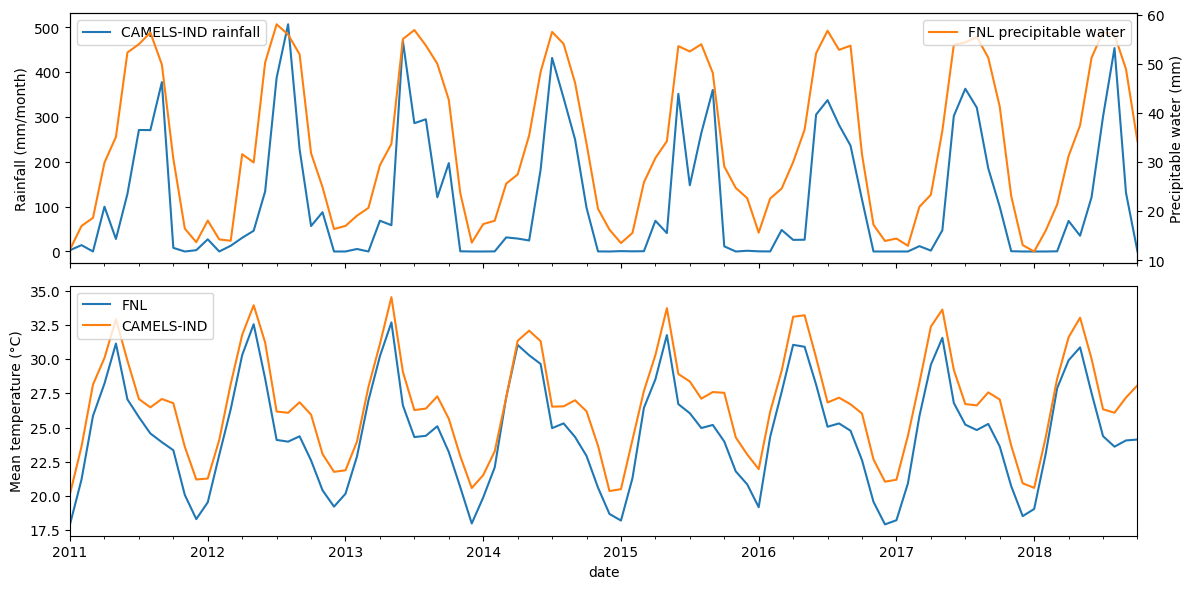

Daily correlation with CAMELS-IND rainfall:
  FNL pwat    : 0.424
  FNL soilw   : 0.410
  FNL rel_hum : 0.416


In [ ]:
import matplotlib.pyplot as plt

daily, gaps_before, gaps_after = build_daily(raw, DATA_START, TEST_END)
daily.to_csv(os.path.join(WORK, f"fnl_daily_{BASIN_ID}.csv"))
print(f"FNL daily variables: {list(daily.columns)}")
print(f"Days with missing values: {gaps_before} (after filling gaps up to 3 days: {gaps_after})")
display(daily.describe().T.round(2))

imd = basin_df.loc[DATA_START:TEST_END]
fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
if "prcp" in imd:
    imd["prcp"].resample("MS").sum().plot(ax=ax[0], color="tab:blue", label="CAMELS-IND rainfall")
    ax[0].set_ylabel("Rainfall (mm/month)")
if "prcp" in daily:
    daily["prcp"].resample("MS").sum().plot(ax=ax[0], color="tab:green", label="FNL rainfall")
if "pwat" in daily:
    ax2 = ax[0].twinx()
    daily["pwat"].resample("MS").mean().plot(ax=ax2, color="tab:orange", label="FNL precipitable water")
    ax2.set_ylabel("Precipitable water (mm)")
    ax2.legend(loc="upper right")
ax[0].legend(loc="upper left")
if "tavg" in daily and "tavg" in imd:
    daily["tavg"].resample("MS").mean().plot(ax=ax[1], label="FNL")
    imd["tavg"].resample("MS").mean().plot(ax=ax[1], label="CAMELS-IND")
    ax[1].set_ylabel("Mean temperature (°C)"); ax[1].legend()
plt.tight_layout(); plt.show()

if "prcp" in imd:
    print("Daily correlation with CAMELS-IND rainfall:")
    for c in ("prcp", "pwat", "soilw", "rel_hum"):
        if c in daily:
            print(f"  FNL {c:8s}: {daily[c].corr(imd['prcp']):.3f}")

## Step 7: The three NeuralHydrology setups
* **A: FNL only**: all inputs from FNL (precipitable water and soil moisture instead of rainfall, which FNL lacks before 2019)
* **B: FNL + CAMELS-IND rainfall**: FNL inputs plus observed catchment rainfall
* **C: CAMELS-IND only**: baseline

All three setups use the same observed streamflow, periods and model configuration.

In [ ]:
import torch

FNL_VARS = [c for c in ["tmax", "tmin", "tavg", "rel_hum", "wind", "pwat", "soilw", "prcp"] if c in daily.columns]
IMD_VARS = [c for c in ["prcp", "tmax", "tmin", "tavg", "rel_hum", "wind"] if c in basin_df.columns]
target = basin_df["streamflow_mm_day"]
imd_part = basin_df.loc[DATA_START:TEST_END]

setups = [("A: FNL only", "fnl_only", daily[FNL_VARS])]
if "prcp" not in FNL_VARS and "prcp" in basin_df.columns:
    setups.append(("B: FNL + CAMELS-IND rainfall", "fnl_plus_rain",
                   daily[FNL_VARS].join(imd_part[["prcp"]], how="left")))
setups.append(("C: CAMELS-IND only", "camels_only", imd_part[IMD_VARS]))

basin_file = os.path.join(WORK, "basin_list.txt")
with open(basin_file, "w") as f:
    f.write(f"{BASIN_ID}\n")
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
RUN_ROOT = os.path.join(WORK, "runs")

CONFIGS = {}
for label, name, forcing in setups:
    df_ = write_nh_dataset(os.path.join(WORK, f"data_{name}"), forcing, target, ATTR_CSV, BASIN_ID)
    inputs = usable_inputs(df_, list(forcing.columns), PERIODS["train"], label)
    counts = {k: count_valid_samples(df_, inputs, p, SEQ_LENGTH) for k, p in PERIODS.items()}
    print(f"{label}\n    inputs: {inputs}\n    valid samples: {counts}")
    if counts["train"] == 0:
        raise RuntimeError(f"[{label}] no valid training samples. Usually DATA_START is not at least "
                           f"SEQ_LENGTH ({SEQ_LENGTH}) days before TRAIN_START, or there is no observed "
                           "flow / too many gaps in the training period.")
    if min(counts.values()) < 60:
        print(f"    WARNING: few samples in some period; results will be noisy.")
    CONFIGS[label] = (name, write_config(name, os.path.join(WORK, f"data_{name}"), inputs, basin_file,
                                         PERIODS, EPOCHS, SEQ_LENGTH, DEVICE, RUN_ROOT))
print("\nTraining device:", DEVICE)

A: FNL only
    inputs: ['tmax', 'tmin', 'tavg', 'rel_hum', 'wind', 'pwat', 'soilw']
    valid samples: {'train': 889, 'val': 142, 'test': 407}
B: FNL + CAMELS-IND rainfall
    inputs: ['tmax', 'tmin', 'tavg', 'rel_hum', 'wind', 'pwat', 'soilw', 'prcp']
    valid samples: {'train': 889, 'val': 142, 'test': 407}
C: CAMELS-IND only
    inputs: ['prcp', 'tmax', 'tmin', 'tavg', 'rel_hum', 'wind']
    valid samples: {'train': 889, 'val': 142, 'test': 407}

Training device: cpu


## Step 8: Training

In [ ]:
from pathlib import Path
from neuralhydrology.nh_run import start_run

for label, (name, cfg) in CONFIGS.items():
    print(f"\n========== Training {label} ==========")
    start_run(config_file=Path(cfg))


========== Training A: FNL only ==========
# Validation: 100%|██████████| 1/1 [00:00<00:00,  2.87it/s]

========== Training B: FNL + CAMELS-IND rainfall ==========
# Validation: 100%|██████████| 1/1 [00:00<00:00,  2.94it/s]

========== Training C: CAMELS-IND only ==========
# Validation: 100%|██████████| 1/1 [00:00<00:00,  3.08it/s]


## Step 9: Evaluation on the test period

# Evaluation: 100%|██████████| 1/1 [00:00<00:00,  1.41it/s]


,NSE,KGE,RMSE,Pearson-r,Alpha-NSE,Beta-NSE
A: FNL only,-0.008,-0.596,104.589,0.080,0.018,-0.103
B: FNL + CAMELS-IND rainfall,-0.008,-0.606,104.602,0.087,0.020,-0.107
C: CAMELS-IND only,-0.010,-0.632,104.690,0.056,0.017,-0.108


Test period: 407 observed days, 30% zero-flow, largest flow 946.5 mm/day


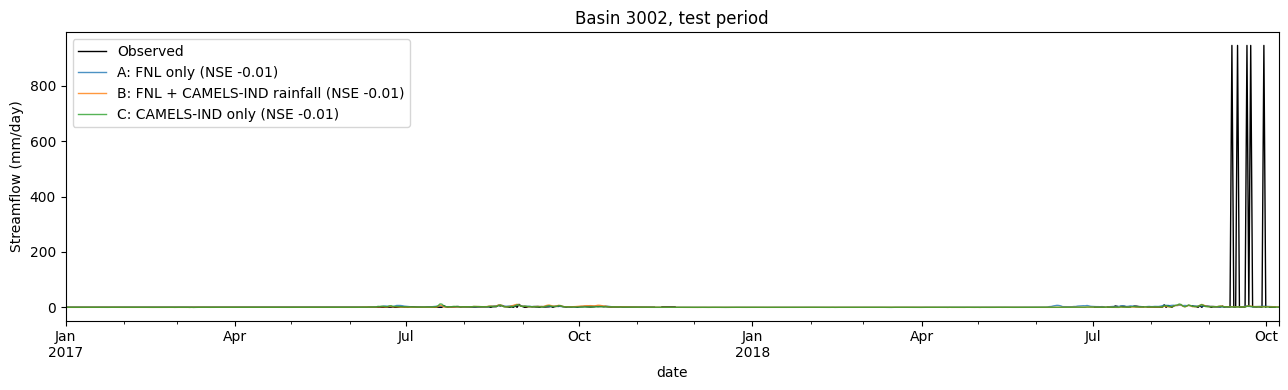

In [ ]:
from neuralhydrology.nh_run import eval_run
from neuralhydrology.evaluation import metrics as nh_metrics

rows, sims, obs = {}, {}, None
for label, (name, _) in CONFIGS.items():
    run_dir = latest_run_dir(RUN_ROOT, name)
    eval_run(run_dir=Path(run_dir), period="test")
    obs, sim = load_test_results(run_dir, BASIN_ID)
    m = nh_metrics.calculate_all_metrics(obs, sim)
    rows[label] = {k: m[k] for k in ("NSE", "KGE", "RMSE", "Pearson-r", "Alpha-NSE", "Beta-NSE") if k in m}
    sims[label] = sim

summary = pd.DataFrame(rows).T.round(3)
summary.to_csv(os.path.join(WORK, "comparison_metrics.csv"))
display(summary)

obs_s = obs.to_series()
print(f"Test period: {int(obs_s.notna().sum())} observed days, "
      f"{(obs_s == 0).mean():.0%} zero-flow, largest flow {obs_s.max():.1f} mm/day")

fig, ax = plt.subplots(figsize=(13, 4))
obs_s.plot(ax=ax, color="black", lw=1, label="Observed")
for label, sim in sims.items():
    sim.to_series().plot(ax=ax, lw=1, alpha=0.8, label=f"{label} (NSE {rows[label]['NSE']:.2f})")
ax.set_ylabel("Streamflow (mm/day)"); ax.set_title(f"Basin {BASIN_ID}, test period")
ax.legend(); plt.tight_layout(); plt.show()

## Step 9b: Test scores without erroneous streamflow values
Five days in September 2018 have the identical value 946.47 mm/day, which is physically implausible for this basin. Values above 100 mm/day are treated as gauge errors and excluded from the scores. None of them lies in the training period, so the trained models are not affected.

Days above 100 mm/day in the whole record:
date
2018-09-13    946.46722
2018-09-16    946.46722
2018-09-21    946.46722
2018-09-23    946.46722
2018-09-30    946.46722

Training-period days above the limit: 0


,NSE,KGE,RMSE,Pearson-r
A: FNL only,-0.301,0.007,1.711,0.634
B: FNL + CAMELS-IND rainfall,-0.390,0.239,1.769,0.574
C: CAMELS-IND only,-0.193,0.380,1.639,0.531


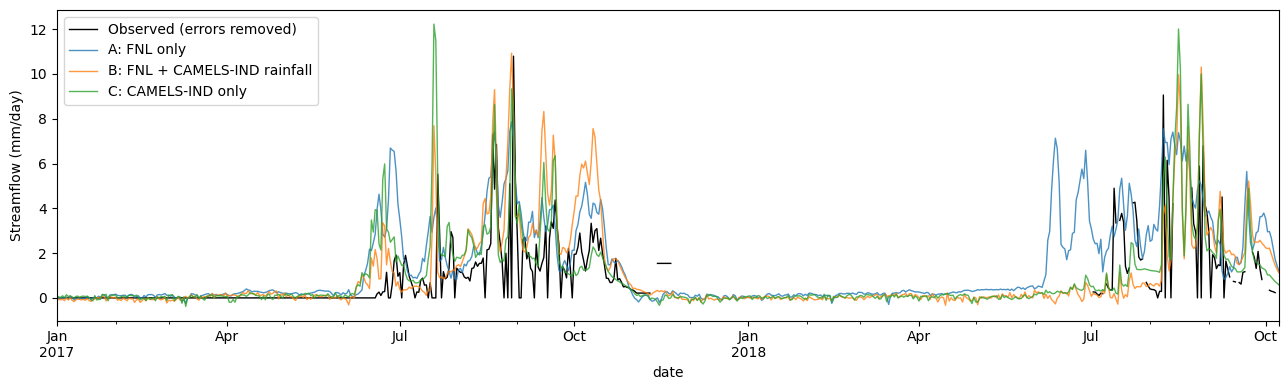

In [ ]:
LIMIT = 100   # mm/day; values above this are treated as gauge errors

q = basin_df["streamflow_mm_day"]
print("Days above", LIMIT, "mm/day in the whole record:")
print(q[q > LIMIT].to_string())
print("\nTraining-period days above the limit:", int((q.loc[TRAIN_START:TRAIN_END] > LIMIT).sum()))

rows2 = {}
for label, sim in sims.items():
    o = obs.where(obs <= LIMIT)          # NaN values are ignored by the metrics
    m = nh_metrics.calculate_all_metrics(o, sim.where(obs <= LIMIT))
    rows2[label] = {k: m[k] for k in ("NSE", "KGE", "RMSE", "Pearson-r")}
display(pd.DataFrame(rows2).T.round(3))

o_s = obs.to_series().where(lambda x: x <= LIMIT)
fig, ax = plt.subplots(figsize=(13, 4))
o_s.plot(ax=ax, color="black", lw=1, label="Observed (errors removed)")
for label, sim in sims.items():
    sim.to_series().plot(ax=ax, lw=1, alpha=0.8, label=label)
ax.set_ylabel("Streamflow (mm/day)"); ax.legend(); plt.tight_layout(); plt.show()

## Step 10: Clean-up of open GDEX requests
Deletes requests that are still open on the GDEX server, for example after an interrupted run.

In [ ]:
EXTRA_REQUEST_IDS = []   # request ids from earlier sessions, if any
for rid in list(OPEN_REQUESTS) + EXTRA_REQUEST_IDS:
    purge_request(rid)
print("Cleanup done.")

Cleanup done.
